# Appendix: Python Primer

[Course contents](../00_course_contents.md)

> **Open course material.** You may download, teach, adapt, and share this notebook with attribution. It can serve a course at any institution, independent study, exam review, or preparation for work in quantum technology. See the [reuse terms](../LICENSE), the [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and the [citation metadata](../CITATION.cff).

## Learning goals

- Distinguish Markdown cells from executable code cells.
- Use variables, functions, NumPy arrays, loops, conditionals, and Matplotlib.
- Represent quantum states with complex arrays and apply the correct conjugation, tensor-product, and normalization operations.


In [1]:
from pathlib import Path

Path.cwd().name  # show only the current folder name, not a machine-specific path


'appendices'

In [2]:
# Keep notebooks portable: store relative paths and resolve them only when needed.
notebook_folder = Path('.')
notebook_folder


WindowsPath('.')

## Code and Markdown cells

Code cells execute Python. Markdown cells organize explanations with headings, lists, links, equations, and images. A useful notebook alternates short explanations with small executable examples so that every numerical claim can be checked close to where it is introduced.


## Examples of Markdown in Jupyter notebooks

### 1. Writing formulas with LaTeX

To write formulas in Markdown, use `$` for inline formulas or `$$` for block formulas:

Inline example: $E = mc^2$

Block example:

$$
\int_{a}^{b} f(x) dx = F(b) - F(a)
$$


### 2. Inline code and emphasis

Backticks mark names and short code fragments such as `np.array`. Use **bold** for strong emphasis and *italics* for terminology; neither changes program execution.


### 3. Linking a course video

GitHub does not reliably render notebook `iframe` elements. A normal watch link works in Jupyter, GitHub, and exported HTML:

[Quantum Computing 2.0: Lecture 2 (QTM Lab)](https://www.youtube.com/watch?v=sNvC0DAhVpg)


## Installing the scientific Python environment

NumPy provides numerical arrays, SciPy provides scientific algorithms, SymPy performs symbolic algebra, Matplotlib produces figures, QuTiP models quantum dynamics, and Qiskit constructs and executes quantum circuits. Install the course environment once from the repository root:

```bash
python -m pip install -r requirements.txt
```

Use a virtual environment so that course dependencies do not alter the system Python installation.


In [3]:
# Dependencies are installed once from requirements.txt, outside the notebook.
import numpy as np

print("NumPy version:", np.__version__)


NumPy version: 2.5.2


In [4]:
import numpy as np
import sympy as sp

pi = np.pi


## Variables

In Python, variables store data values and are created by assigning a value using the `=` operator. Variable names must start with a letter or underscore, cannot start with a number, and are case-sensitive. Example: `variable_name = 10`.


In [5]:
# Variables
a = 10
b = 5

(a, b)  # a tuple displays both values in one notebook output


(10, 5)

In [6]:
print(a)
print(b)

10
5


Jupyter displays the value of the final bare expression in a cell. Use `print(...)` for labeled output or collect several values in a tuple, list, or dictionary.


In [7]:
integer_value = 10
floating_value = 3.14
message = 'Hello, Quantum World!'

(integer_value, floating_value, message)


(10, 3.14, 'Hello, Quantum World!')

In [8]:
a = 10
b = 5

(a, b)


(10, 5)

In [9]:
operations = {
    'sum': a + b,
    'difference': a - b,
    'product': a * b,
    'power': a**b,
    'division': a / b,
    'floor division': a // b,
}
operations


{'sum': 15,
 'difference': 5,
 'product': 50,
 'power': 100000,
 'division': 2.0,
 'floor division': 2}

## Functions

Functions are defined with `def`, followed by a name, parameters, and an indented body:

```python
def function_name(parameters):
    # code block
    return value
```


In [10]:
def sine(x):
    return np.sin(x)


In [11]:
def greet(name):
    return 'Hello, ' + name

In [12]:
greet('Alex')

'Hello, Alex'

In [13]:
numerical_values = (sine(np.pi / 2), np.cos(np.pi))

degrees = 45
theta = np.deg2rad(degrees)
exact_value = sp.sin(sp.pi / 4)

(numerical_values, theta, exact_value, sp.N(exact_value))


((np.float64(1.0), np.float64(-1.0)),
 np.float64(0.7853981633974483),
 sqrt(2)/2,
 0.707106781186548)

## Lists, arrays, vectors, and matrices

- A Python `list` can contain heterogeneous objects.
- A NumPy array has a shape and a single `dtype` (which can be `object` when needed).
- A one-dimensional array of shape `(n,)` is often used for a vector; an explicit column has shape `(n, 1)`.
- A matrix is naturally represented as a two-dimensional array. Use `@` for matrix multiplication and `*` for elementwise multiplication.


In [14]:
items = [1, 2, 3, 'four', 5.0, 'Alex']
print(items)


[1, 2, 3, 'four', 5.0, 'Alex']


In [15]:
# One-dimensional vector and explicit column-vector representations
vector_1d = np.array([1, 2, 3, 4, 5])
column_vector = np.array([[1], [2], [3], [4], [5]])

(vector_1d.shape, column_vector.shape)


((5,), (5, 1))

In [16]:

zeros = np.zeros(4)
ones_column = np.ones(3).reshape(-1, 1)
zeros, ones_column


(array([0., 0., 0., 0.]),
 array([[1.],
        [1.],
        [1.]]))

In [17]:
# Approximate surface gravity from Newton's law of gravitation
G = 6.67430e-11       # m^3 kg^-1 s^-2
earth_mass = 5.972e24 # kg
earth_radius = 6.371e6 # m

surface_gravity = G * earth_mass / earth_radius**2
surface_gravity


9.819973426224687

In [18]:
import sympy as sp

In [19]:
exact_root = sp.sqrt(2)
approximate_root = sp.N(exact_root, 12)
(exact_root, approximate_root)


(sqrt(2), 1.41421356237)

## Loops and conditionals


### `for` loops

A `for` loop iterates over a sequence:

```python
for variable in sequence:
    # indented code block
```


In [20]:
# For loop 

for i in range(5):
    print(i)

0
1
2
3
4


### `if` / `else`

Conditionals select a code path:

```python
if condition:
    # executed when True
else:
    # executed when False
```


In [21]:
#  If-Else Conditionals

x = 0
if x > 0:
    print("Positive")
else:
    print("Non-positive")


Non-positive


### `while` loops

A `while` loop repeats while its condition is true:

```python
while condition:
    # update state so the loop eventually terminates
```


In [22]:
# While Conditional

count = 0

while count < 5:
    print("Count is:", count) # Print count
    count += 1  # Update: Increment by 1

print("Loop ended when count reached 5") # Printed last


Count is: 0
Count is: 1
Count is: 2
Count is: 3
Count is: 4
Loop ended when count reached 5


In [23]:
# Vectors represented as NumPy arrays
A = np.array([1.0, 2.0, -1.0])
A


array([ 1.,  2., -1.])

In [24]:
B = np.array([3.0, 2.0, 1.0])

print("A + B =", A + B)
print("A dot B =", np.dot(A, B))
print("A cross B =", np.cross(A, B))


A + B = [4. 4. 0.]
A dot B = 6.0
A cross B = [ 4. -4. -4.]


In [25]:
# Vector components
A[0], B[1]


(np.float64(1.0), np.float64(2.0))

In [26]:
# Euclidean norm
np.linalg.norm(A)


np.float64(2.449489742783178)

In [27]:
# Normalization
A_unit = A / np.linalg.norm(A)
A_unit


array([ 0.40824829,  0.81649658, -0.40824829])

### Example: uniformly accelerated motion

For constant acceleration $a$, integrating $a=dv/dt$ twice gives

$$v(t)=v_0+at,\qquad x(t)=x_0+v_0t+\frac12at^2.$$

Equivalently, the displacement from the initial position is $\Delta x=x(t)-x_0=v_0t+\tfrac12at^2$, which is the convention used in the figure.

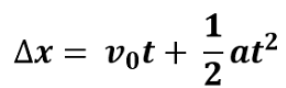


In [28]:
x0 = 0.0
v0 = 1.0
acceleration = -0.3
dt = 0.5
t_final = 10.0

t = 0.0
while t + dt <= t_final + 1e-12:
    t += dt
    x = x0 + v0 * t + 0.5 * acceleration * t**2
    print(f"t={t:4.1f}, x={x:7.3f}")


t= 0.5, x=  0.463
t= 1.0, x=  0.850
t= 1.5, x=  1.163
t= 2.0, x=  1.400
t= 2.5, x=  1.562
t= 3.0, x=  1.650
t= 3.5, x=  1.663
t= 4.0, x=  1.600
t= 4.5, x=  1.462
t= 5.0, x=  1.250
t= 5.5, x=  0.963
t= 6.0, x=  0.600
t= 6.5, x=  0.163
t= 7.0, x= -0.350
t= 7.5, x= -0.938
t= 8.0, x= -1.600
t= 8.5, x= -2.338
t= 9.0, x= -3.150
t= 9.5, x= -4.037
t=10.0, x= -5.000


In [29]:
# Construct the same trajectory as NumPy arrays.
x0 = 0.0
v0 = 1.0
acceleration = -0.3
dt = 0.5
t_final = 10.0

time = np.arange(dt, t_final + 0.5 * dt, dt)
position = x0 + v0 * time + 0.5 * acceleration * time**2


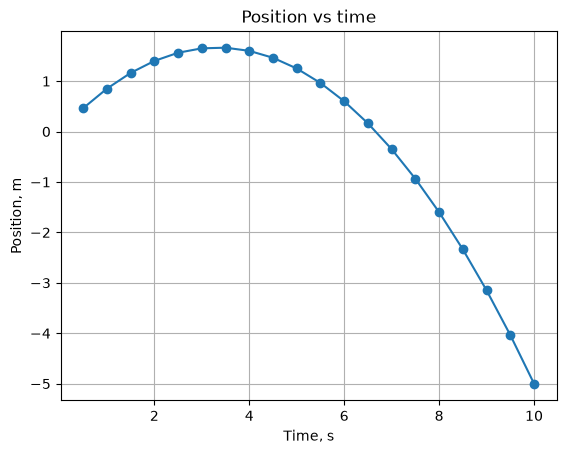

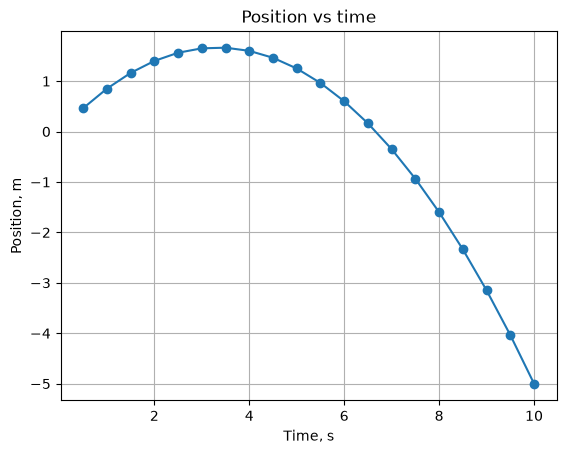

In [30]:
%matplotlib inline

# Matplotlib
import matplotlib.pyplot as plt


fig, ax = plt.subplots()
ax.plot(time, position, linestyle='-', marker='o')
ax.set(xlabel='Time, s', ylabel='Position, m', title='Position vs time')
ax.grid(True)
fig

*The position follows a downward-opening parabola: it rises while the initial velocity dominates, reaches a maximum when the velocity crosses zero, and then falls under constant negative acceleration.*


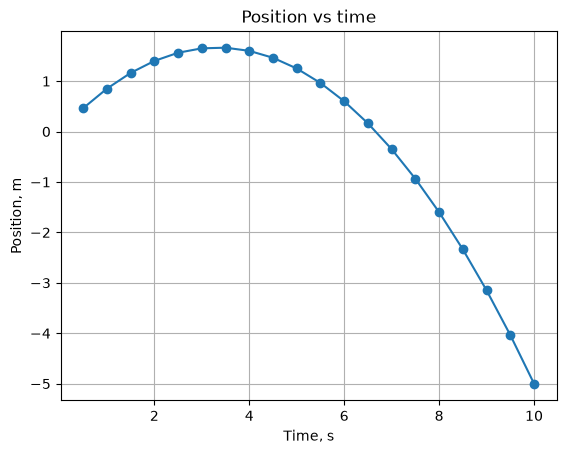

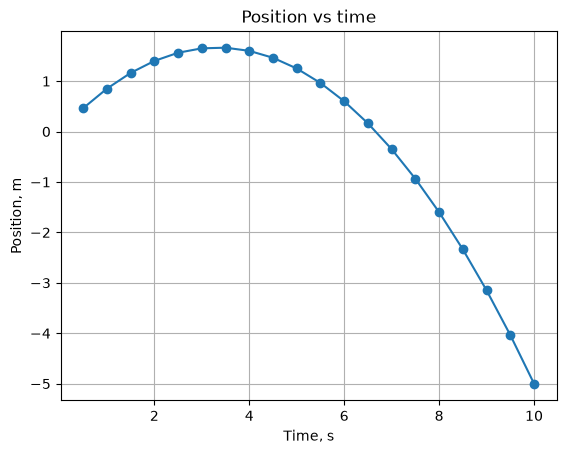

In [31]:
# The same calculation with explicit for-loop syntax.
time_loop = []
position_loop = []

for step in range(1, int(round(t_final / dt)) + 1):
    t_value = step * dt
    x_value = x0 + v0 * t_value + 0.5 * acceleration * t_value**2
    time_loop.append(t_value)
    position_loop.append(x_value)

fig, ax = plt.subplots()
ax.plot(time_loop, position_loop, linestyle='-', marker='o')
ax.set(xlabel='Time, s', ylabel='Position, m', title='Position vs time')
ax.grid(True)
fig


*The explicit loop reproduces the same position-versus-time parabola as the vectorized NumPy calculation, which gives a visual check that the two methods agree.*


## Quantum-oriented NumPy patterns

Quantum state vectors require a complex data type. For vectors $u$ and $v$, `np.vdot(u, v)` computes $u^\dagger v$ and therefore conjugates the first vector. `np.kron` constructs tensor products, `@` performs matrix multiplication, and `np.linalg.norm` computes the Euclidean norm. Floating-point identities should be tested with `np.allclose` rather than exact equality.

For a normalized state $|\psi\rangle$, the density matrix is $\rho=|\psi\rangle\langle\psi|$, and computational-basis probabilities are $p_k=|\psi_k|^2$.


In [32]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)
plus = (ket0 + ket1) / np.sqrt(2)

X = np.array([[0, 1], [1, 0]], dtype=complex)
rho_plus = np.outer(plus, plus.conj())
probabilities = np.abs(plus)**2

print('norm:', np.linalg.norm(plus))
print('<0|+>:', np.vdot(ket0, plus))
print('|0> tensor |1>:', np.kron(ket0, ket1))
print('X|0> equals |1>:', np.allclose(X @ ket0, ket1))
print('trace(rho):', np.trace(rho_plus))
print('basis probabilities:', probabilities)


norm: 0.9999999999999999
<0|+>: (0.7071067811865475+0j)
|0> tensor |1>: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
X|0> equals |1>: True
trace(rho): (0.9999999999999998+0j)
basis probabilities: [0.5 0.5]


## References

1. [The Python tutorial](https://docs.python.org/3/tutorial/).
2. [NumPy quickstart](https://numpy.org/doc/stable/user/quickstart.html).
3. [NumPy linear algebra](https://numpy.org/doc/stable/reference/routines.linalg.html).
4. [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html).
5. [Jupyter documentation](https://docs.jupyter.org/en/latest/).
6. [Qiskit bit-ordering conventions](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).
